In [5]:
#loading the libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

In [6]:
# calling the database 
load_dotenv(find_dotenv(usecwd=True), override=True)

url = URL.create(
    "postgresql+psycopg2",
    username=os.environ["DB_USER"],
    password=os.environ["DB_PASSWORD"],
    host=os.environ["DB_HOST"],
    port=int(os.environ["DB_PORT"]),
    database=os.environ["DB_NAME"],
)
engine = create_engine(url)

with engine.connect() as conn:
    print(conn.execute(text("SELECT current_user")).scalar())

kirema


In [7]:
#loading the tables 
names = ["customers", "geolocation", "order_items", "order_payments",
         "order_reviews", "orders", "products", "sellers"]

data = {}
for name in names:
    df = pd.read_sql(f"SELECT * FROM staging.{name}", engine)
    data[name] = df.replace(r"^\s*$", np.nan, regex=True)
    print(f"{name}: {df.shape[0]:,} rows, {df.shape[1]} columns")

customers: 99,441 rows, 5 columns
geolocation: 19,015 rows, 5 columns
order_items: 112,650 rows, 7 columns
order_payments: 103,886 rows, 5 columns
order_reviews: 99,224 rows, 7 columns
orders: 99,441 rows, 8 columns
products: 32,951 rows, 10 columns
sellers: 3,095 rows, 4 columns


In [9]:
#renaming the colums 
rename_map = {
    "orders": {
        "purchased_at": "order_purchase_timestamp",
        "delivered_at": "order_delivered_customer_date",
        "estimated_delivery_at": "order_estimated_delivery_date",
    },
    "order_items": {
        "item_seq": "order_item_id",
    },
    "order_payments": {
        "installments": "payment_installments",
    },
    "products": {
        "category": "product_category_name",
        "weight_g": "product_weight_g",
    },
    "sellers": {
        "state": "seller_state",
    },
    "geolocation": {
        "lat": "geolocation_lat",
        "lng": "geolocation_lng",
    },
}

for table, mapping in rename_map.items():
    data[table] = data[table].rename(columns=mapping)

print("Columns renamed.")

Columns renamed.


In [10]:
#checking the colums names
required = {
    "customers": ["customer_id", "customer_unique_id", "state"],
    "orders": ["order_id", "customer_id", "order_status", "order_purchase_timestamp",
               "order_delivered_customer_date", "order_estimated_delivery_date"],
    "order_items": ["order_id", "order_item_id", "product_id", "seller_id",
                    "price", "freight_value"],
    "order_payments": ["order_id", "payment_type", "payment_installments", "payment_value"],
    "order_reviews": ["order_id", "review_score"],
    "products": ["product_id", "product_category_name", "product_weight_g"],
    "sellers": ["seller_id", "seller_state"],
    "geolocation": ["geolocation_lat", "geolocation_lng"],
}

problems = False
for table, cols in required.items():
    missing = [c for c in cols if c not in data[table].columns]
    if missing:
        problems = True
        print(f"{table} is missing: {missing}")
        print(f"  Available: {list(data[table].columns)}\n")

if not problems:
    print("All required columns found.")

All required columns found.


In [11]:
#converting type and define chart helpers
customers = data["customers"].copy()
orders = data["orders"].copy()
items = data["order_items"].copy()
payments = data["order_payments"].copy()
reviews = data["order_reviews"].copy()
products = data["products"].copy()
sellers = data["sellers"].copy()
geo = data["geolocation"].copy()

for col in ["order_purchase_timestamp", "order_delivered_customer_date",
            "order_estimated_delivery_date"]:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

for df, cols in [
    (items, ["price", "freight_value"]),
    (payments, ["payment_installments", "payment_value"]),
    (reviews, ["review_score"]),
    (products, ["product_weight_g"]),
    (geo, ["geolocation_lat", "geolocation_lng"]),
]:
    for col in cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")


def bar_chart(series, title, xlabel="Count", fmt="{:,.0f}"):
    fig, ax = plt.subplots(figsize=(10, max(4, len(series) * 0.4)))
    bars = ax.barh(series.index.astype(str), series.values)
    ax.bar_label(bars, labels=[fmt.format(v) for v in series.values], padding=3)
    ax.invert_yaxis()
    ax.margins(x=0.15)
    ax.set(title=title, xlabel=xlabel)
    plt.tight_layout()
    plt.show()


def histogram(series, title, xlabel, clip=0.99):
    s = series.dropna()
    s = s[s <= s.quantile(clip)]
    fig, ax = plt.subplots()
    ax.hist(s, bins=50, edgecolor="white")
    ax.set(title=f"{title} (values up to percentile {clip:.0%})",
           xlabel=xlabel, ylabel="Count")
    plt.tight_layout()
    plt.show()

In [12]:
#structure and statics 
for name, df in data.items():
    print(f"\n===== {name.upper()} =====")
    df.info()
    display(df.head())

for df in [items, payments, reviews, products]:
    display(df.describe().T)


===== CUSTOMERS =====
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   customer_id         99441 non-null  str  
 1   customer_unique_id  99441 non-null  str  
 2   zip_prefix          99441 non-null  str  
 3   city                99441 non-null  str  
 4   state               99441 non-null  str  
dtypes: str(5)
memory usage: 3.8 MB


,customer_id,customer_unique_id,zip_prefix,city,state
0,55d125012ed8410157deac328f196288,2699b1bdee690329303fb2c0aada1c1b,87900,Loanda,Paraná
1,ed9f0ee66c055c608a8953f2def538f1,5657f9f721c16800a66c21081d46b18d,05777,Sao Paulo,São Paulo
2,7203adde3a9d76f21c2b01223d07c2b0,e1cb618b74d0ca68e0c206f386ad15ee,49090,Aracaju,Sergipe
3,032d6bd82e311f4161259e489edbc6c4,f5dd4480c44d03775bc73f63771d987d,08344,Sao Paulo,São Paulo
4,76523bb9cbac54a9e190b9f652762a27,4a082cdc26d0f9de49a440e51ffe55ad,45654,Ilheus,Bahia



===== GEOLOCATION =====
<class 'pandas.DataFrame'>
RangeIndex: 19015 entries, 0 to 19014
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   zip_prefix       19015 non-null  str    
 1   geolocation_lat  19015 non-null  float64
 2   geolocation_lng  19015 non-null  float64
 3   city             19015 non-null  str    
 4   state            19015 non-null  str    
dtypes: float64(2), str(3)
memory usage: 742.9 KB


,zip_prefix,geolocation_lat,geolocation_lng,city,state
0,01001,-23.550190,-46.634024,Sao Paulo,SP
1,01002,-23.548146,-46.634979,Sao Paulo,SP
2,01003,-23.548994,-46.635731,Sao Paulo,SP
3,01004,-23.549799,-46.634757,Sao Paulo,SP
4,01005,-23.549456,-46.636733,Sao Paulo,SP



===== ORDER_ITEMS =====
<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   order_id           112650 non-null  str           
 1   order_item_id      112650 non-null  int64         
 2   product_id         112650 non-null  str           
 3   seller_id          112650 non-null  str           
 4   shipping_limit_at  112650 non-null  datetime64[us]
 5   price              112650 non-null  float64       
 6   freight_value      112650 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(3)
memory usage: 6.0 MB


,order_id,order_item_id,product_id,seller_id,shipping_limit_at,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


... (10 outputs left out)

,count,mean,min,25%,50%,75%,max,std
order_item_id,112650.0,1.197834,1.0,1.0,1.0,1.0,21.0,0.705124
shipping_limit_at,112650,2018-01-07 15:36:52.192685,2016-09-19 00:15:34,2017-09-20 20:57:27.500000,2018-01-26 13:59:35,2018-05-10 14:34:00.750000,2020-04-09 22:35:08,NaN
price,112650.0,120.653739,0.85,39.9,74.99,134.9,6735.0,183.633928
freight_value,112650.0,19.99032,0.0,13.08,16.26,21.15,409.68,15.806405


,count,mean,std,min,25%,50%,75%,max
payment_seq,103886.0,1.092679,0.706584,1.0,1.00,1.0,1.0000,29.00
payment_installments,103886.0,2.853349,2.687051,0.0,1.00,1.0,4.0000,24.00
payment_value,103886.0,154.100380,217.494064,0.0,56.79,100.0,171.8375,13664.08


,count,mean,min,25%,50%,75%,max,std
review_score,99224.0,4.086421,1.0,4.0,5.0,5.0,5.0,1.347579
created_at,99224,2018-01-12 20:49:23.948238,2016-10-02 00:00:00,2017-09-23 00:00:00,2018-02-02 00:00:00,2018-05-16 00:00:00,2018-08-31 00:00:00,NaN
answered_at,99224,2018-01-16 00:23:56.977938,2016-10-07 18:32:28,2017-09-27 01:53:27.250000,2018-02-04 22:41:47.500000,2018-05-20 12:11:21.500000,2018-10-29 12:27:35,NaN


,count,mean,std,min,25%,50%,75%,max
name_length,32341.0,48.476949,10.245741,5.0,42.0,51.0,57.0,76.0
description_length,32341.0,771.495285,635.115225,4.0,339.0,595.0,972.0,3992.0
photos_qty,32341.0,2.188986,1.736766,1.0,1.0,1.0,3.0,20.0
product_weight_g,32949.0,2276.472488,4282.038731,0.0,300.0,700.0,1900.0,40425.0
length_cm,32949.0,30.815078,16.914458,7.0,18.0,25.0,38.0,105.0
height_cm,32949.0,16.937661,13.637554,2.0,8.0,13.0,21.0,105.0
width_cm,32949.0,23.196728,12.079047,6.0,15.0,20.0,30.0,118.0


,column,missing,percent
25,order_reviews.comment_title,87658,88.343546
26,order_reviews.comment_message,58274,58.729743
35,orders.order_delivered_customer_date,2965,2.981668
38,products.category_pt,610,1.851234
40,products.name_length,610,1.851234
39,products.product_category_name,610,1.851234
41,products.description_length,610,1.851234
42,products.photos_qty,610,1.851234
34,orders.shipped_at,1783,1.793023
33,orders.approved_at,160,0.160899


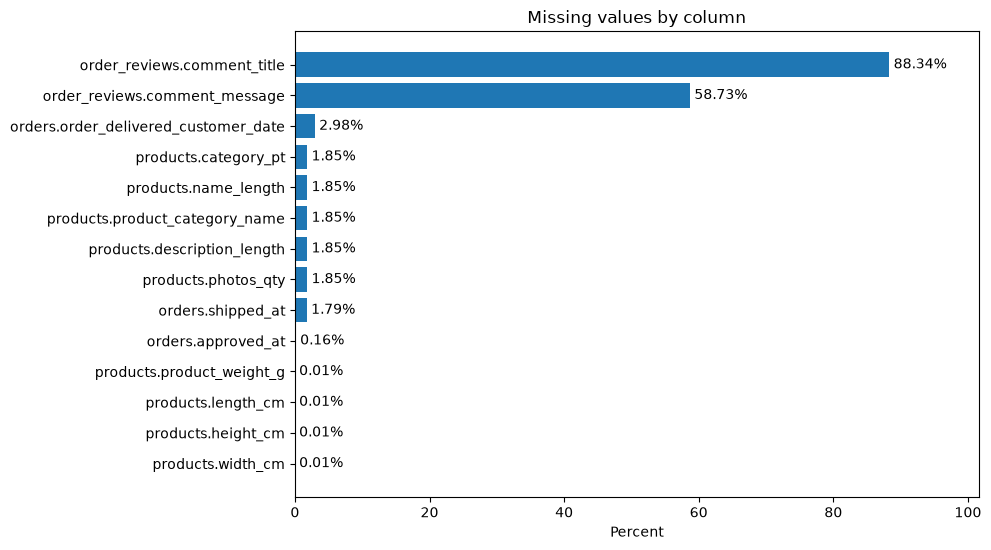

In [13]:
#missing values 
missing = pd.DataFrame([
    {"column": f"{name}.{col}", "missing": df[col].isna().sum(),
     "percent": df[col].isna().mean() * 100}
    for name, df in data.items() for col in df.columns
])
missing = missing[missing["missing"] > 0].sort_values("percent", ascending=False)
display(missing)

if not missing.empty:
    bar_chart(missing.set_index("column")["percent"],
              "Missing values by column", "Percent", "{:.2f}%")

In [14]:
#duplicate and unmatched records
display(pd.Series({n: df.duplicated().sum() for n, df in data.items()},
                  name="duplicate_rows").to_frame())

keys = {"customers": ["customer_id"], "orders": ["order_id"],
        "products": ["product_id"], "sellers": ["seller_id"],
        "order_items": ["order_id", "order_item_id"]}
for table, cols in keys.items():
    print(f"{table} duplicate keys {cols}: {data[table].duplicated(cols).sum()}")

checks = {
    "Orders without a customer": ~orders["customer_id"].isin(customers["customer_id"]),
    "Items without an order": ~items["order_id"].isin(orders["order_id"]),
    "Items without a product": ~items["product_id"].isin(products["product_id"]),
    "Items without a seller": ~items["seller_id"].isin(sellers["seller_id"]),
    "Orders without items": ~orders["order_id"].isin(items["order_id"]),
    "Orders without payment": ~orders["order_id"].isin(payments["order_id"]),
}
for label, mask in checks.items():
    print(f"{label}: {mask.sum():,}")

,duplicate_rows
customers,0
geolocation,0
order_items,0
order_payments,0
order_reviews,0
orders,0
products,0
sellers,0


customers duplicate keys ['customer_id']: 0
orders duplicate keys ['order_id']: 0
products duplicate keys ['product_id']: 0
sellers duplicate keys ['seller_id']: 0
order_items duplicate keys ['order_id', 'order_item_id']: 0
Orders without a customer: 0
Items without an order: 0
Items without a product: 0
Items without a seller: 0
Orders without items: 775
Orders without payment: 1


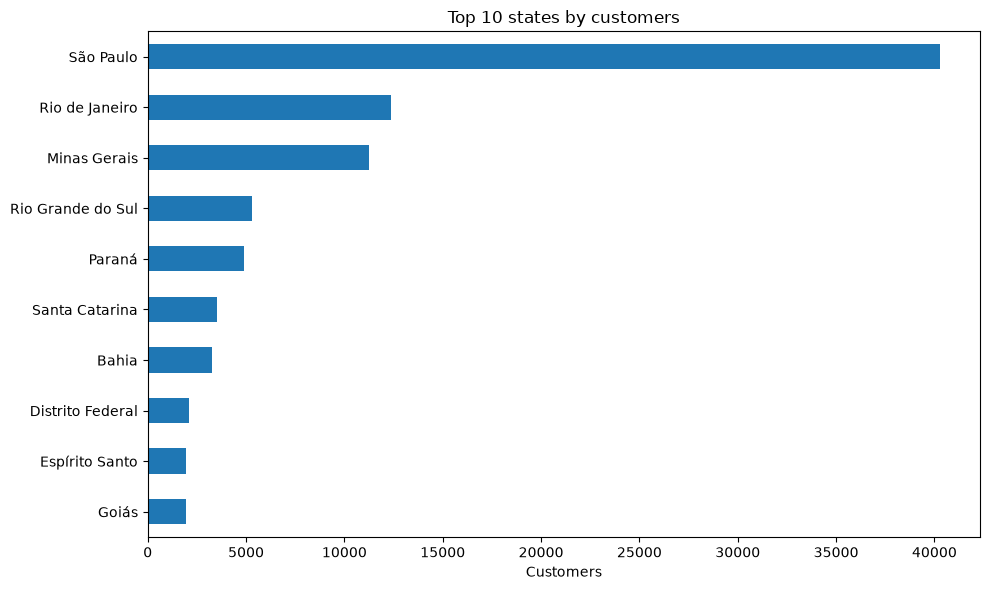

In [ ]:
## customers by state 
query = """
SELECT state, COUNT(DISTINCT customer_unique_id) AS customers
FROM staging.customers
GROUP BY state
ORDER BY customers DESC
LIMIT 10;
"""
df = pd.read_sql(query, engine)

df.plot.barh(x="state", y="customers", legend=False, figsize=(10, 6))
plt.gca().invert_yaxis()
plt.title("Top 10 states by customers")
plt.xlabel("Customers")
plt.ylabel("")
plt.tight_layout()
plt.show()

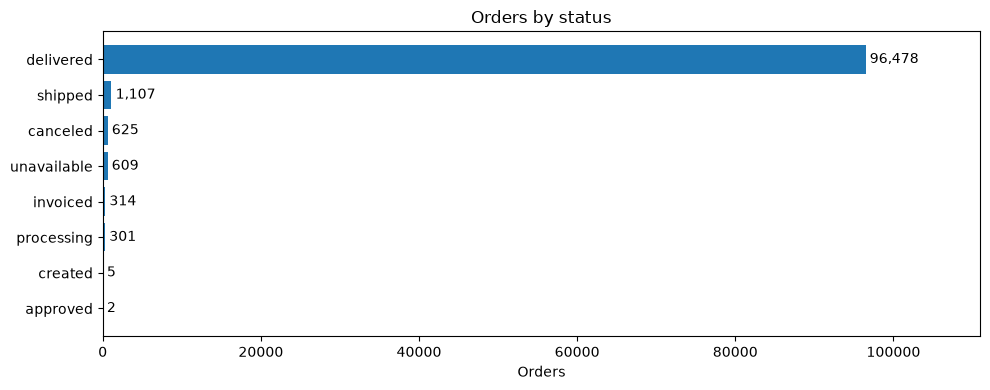

In [15]:
#order status 
bar_chart(orders["order_status"].value_counts(), "Orders by status", "Orders")

Date range: 2016-09-04 21:15:19 to 2018-10-17 17:30:18


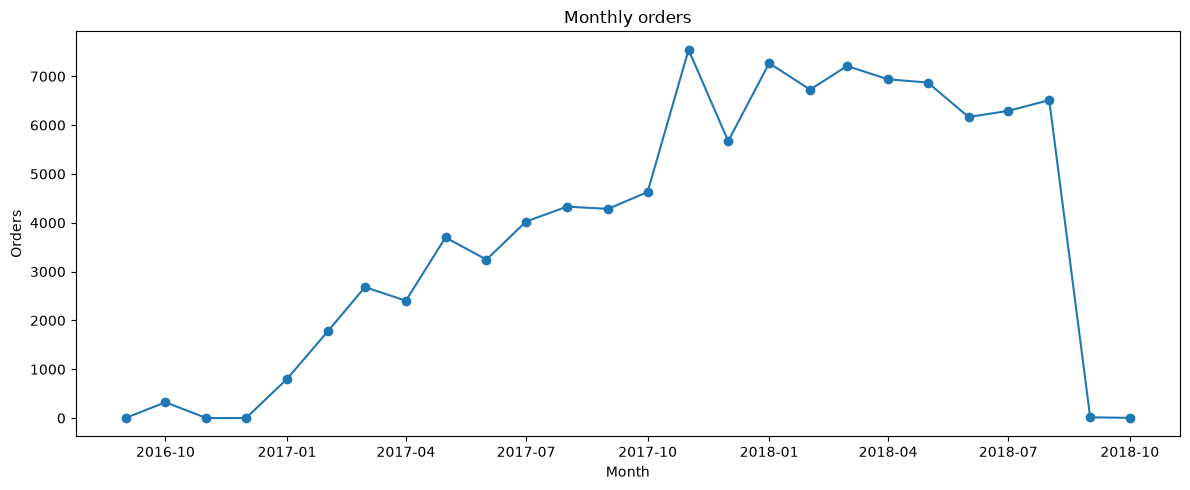

In [16]:
#monthly orders
print("Date range:", orders["order_purchase_timestamp"].min(),
      "to", orders["order_purchase_timestamp"].max())

monthly = orders.dropna(subset=["order_purchase_timestamp"]) \
    .set_index("order_purchase_timestamp").resample("MS")["order_id"].count()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly.index, monthly.values, marker="o")
ax.set(title="Monthly orders", xlabel="Month", ylabel="Orders")
plt.tight_layout()
plt.show()

/tmp/ipykernel_16173/1837185296.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  heat = pd.crosstab(ts.dt.dayofweek, ts.dt.hour).reindex(


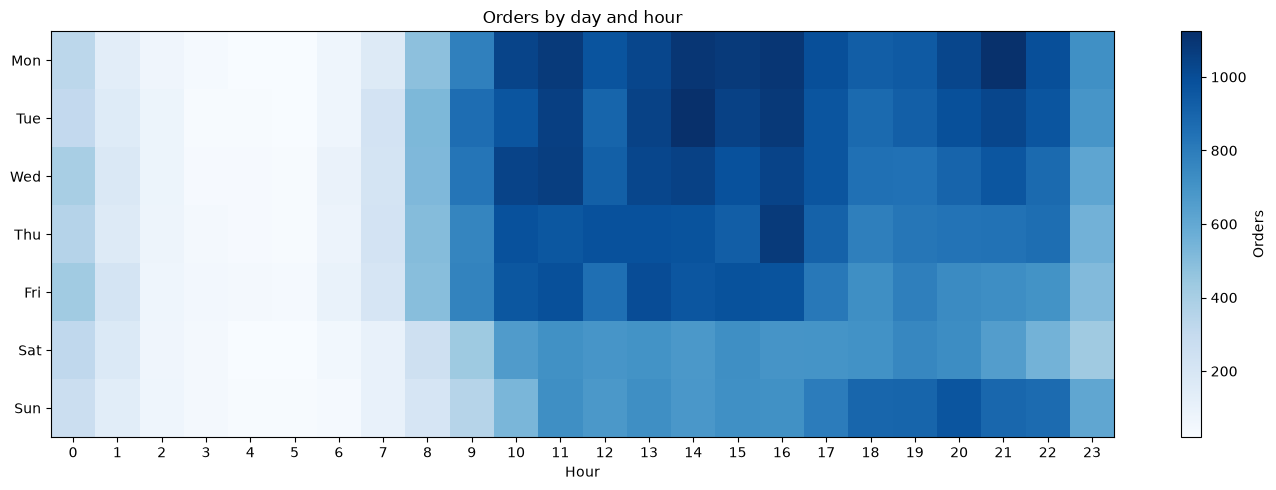

In [17]:
#order by day and hour 
ts = orders["order_purchase_timestamp"].dropna()
heat = pd.crosstab(ts.dt.dayofweek, ts.dt.hour).reindex(
    index=range(7), columns=range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(heat, aspect="auto", cmap="Blues")
ax.set_xticks(range(24))
ax.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set(title="Orders by day and hour", xlabel="Hour")
fig.colorbar(im, ax=ax, label="Orders")
plt.tight_layout()
plt.show()

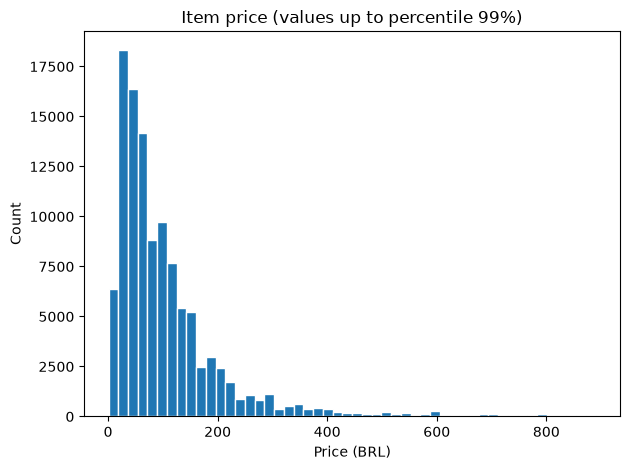

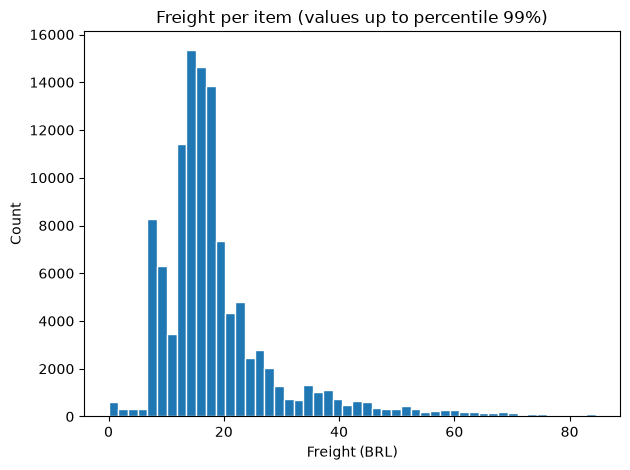

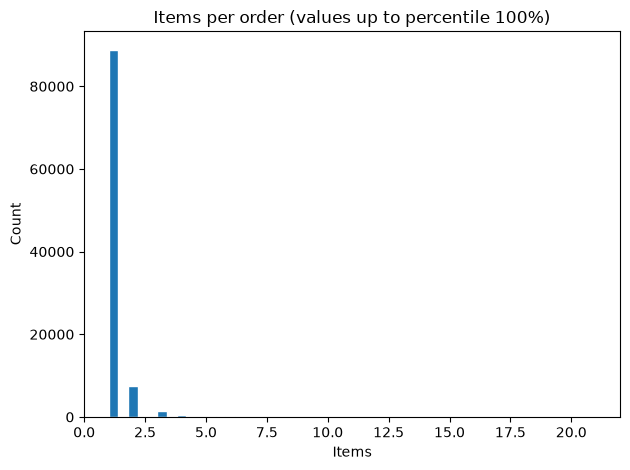

In [18]:
# price and freight 
histogram(items["price"], "Item price", "Price (BRL)")
histogram(items["freight_value"], "Freight per item", "Freight (BRL)")
histogram(items.groupby("order_id").size(), "Items per order", "Items", clip=1.0)


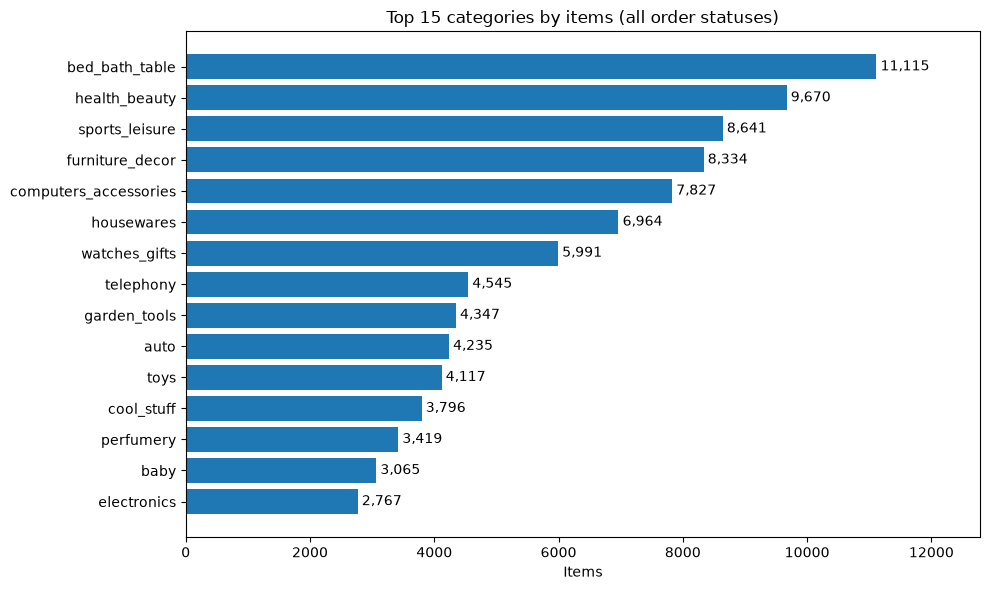

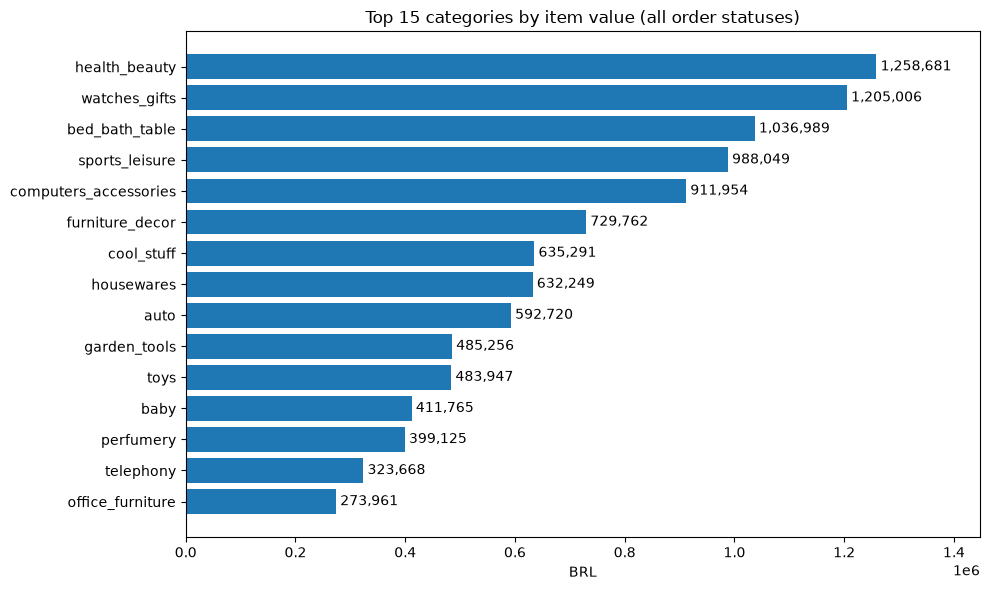

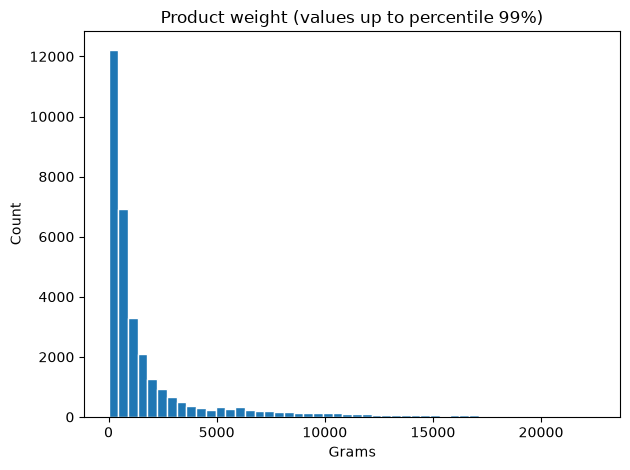

In [19]:
# product categories 
sales = items.merge(products[["product_id", "product_category_name"]],
                    on="product_id", how="left")
sales["product_category_name"] = sales["product_category_name"].fillna("Unknown")
category = sales.groupby("product_category_name").agg(
    items_sold=("order_id", "size"), item_value=("price", "sum"))

bar_chart(category["items_sold"].nlargest(15),
          "Top 15 categories by items (all order statuses)", "Items")
bar_chart(category["item_value"].nlargest(15),
          "Top 15 categories by item value (all order statuses)", "BRL")
histogram(products["product_weight_g"], "Product weight", "Grams")

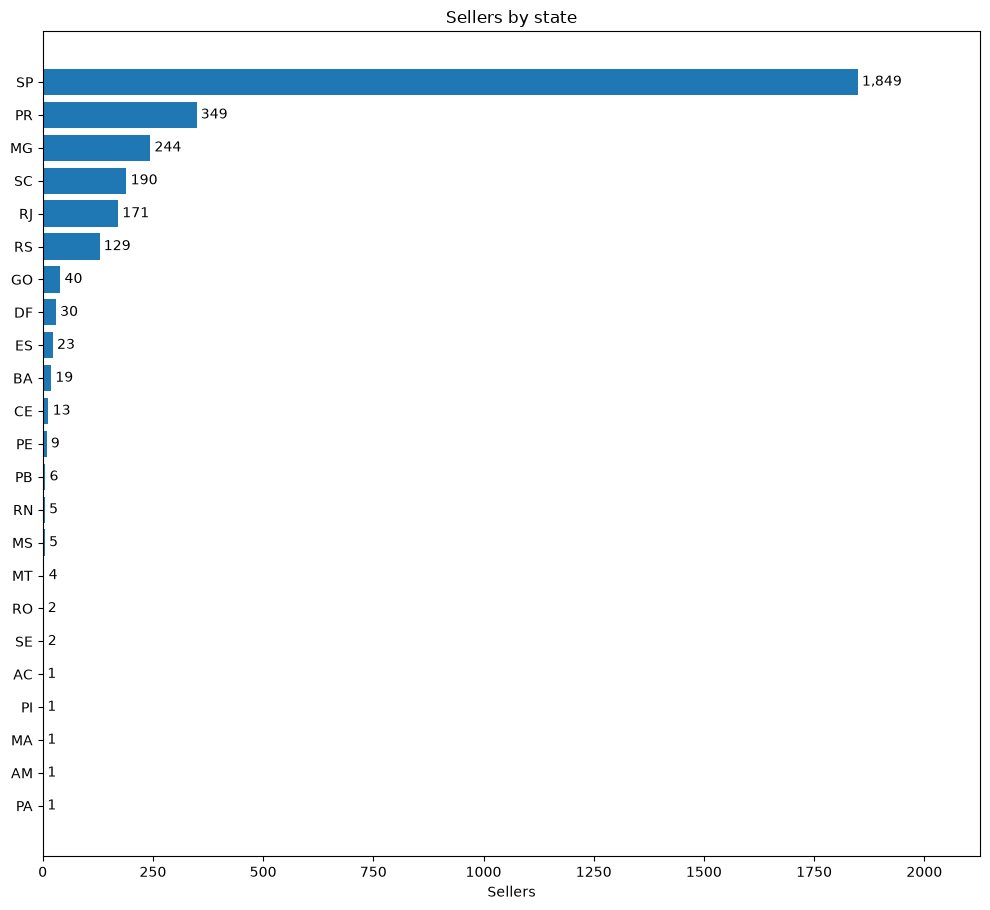

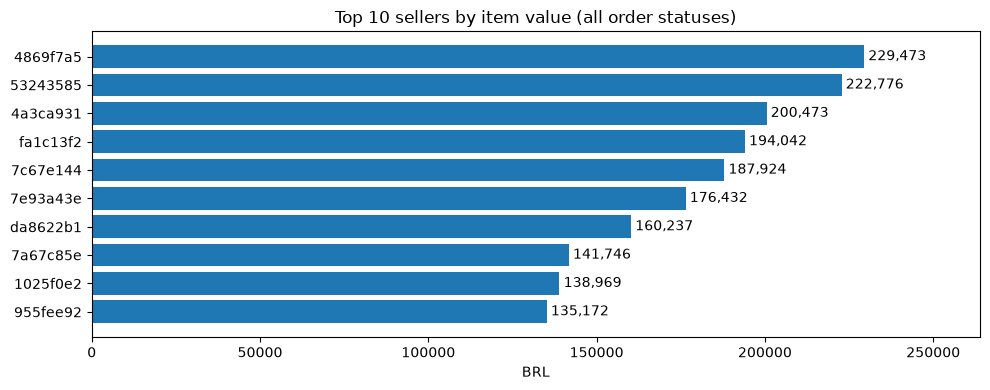

In [22]:
#sellers
bar_chart(sellers["seller_state"].value_counts(), "Sellers by state", "Sellers")

top_sellers = items.groupby("seller_id")["price"].sum().nlargest(10)
top_sellers.index = top_sellers.index.astype(str).str[:8]
bar_chart(top_sellers, "Top 10 sellers by item value (all order statuses)", "BRL")

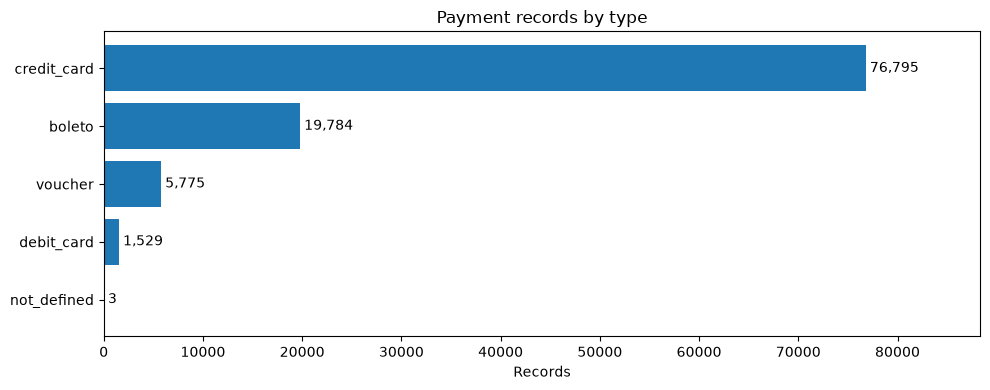

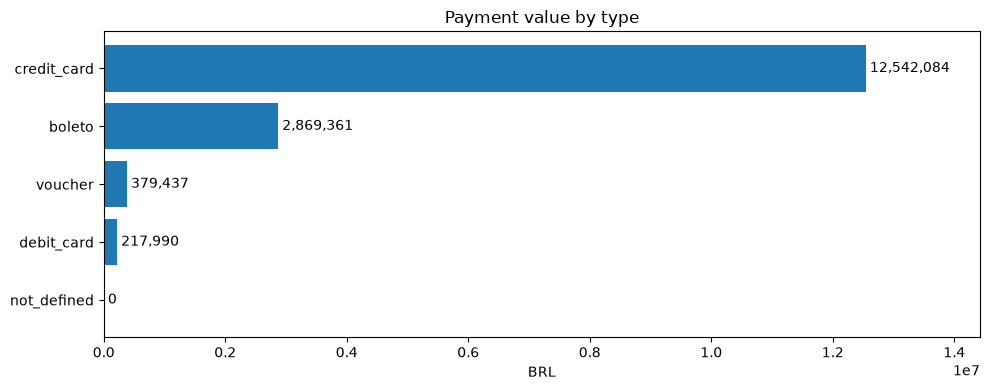

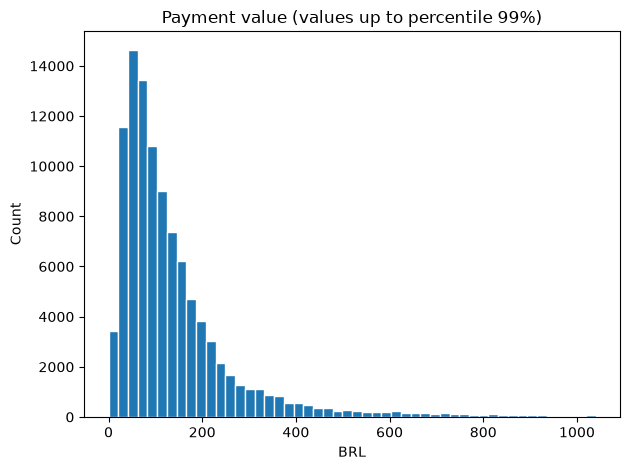

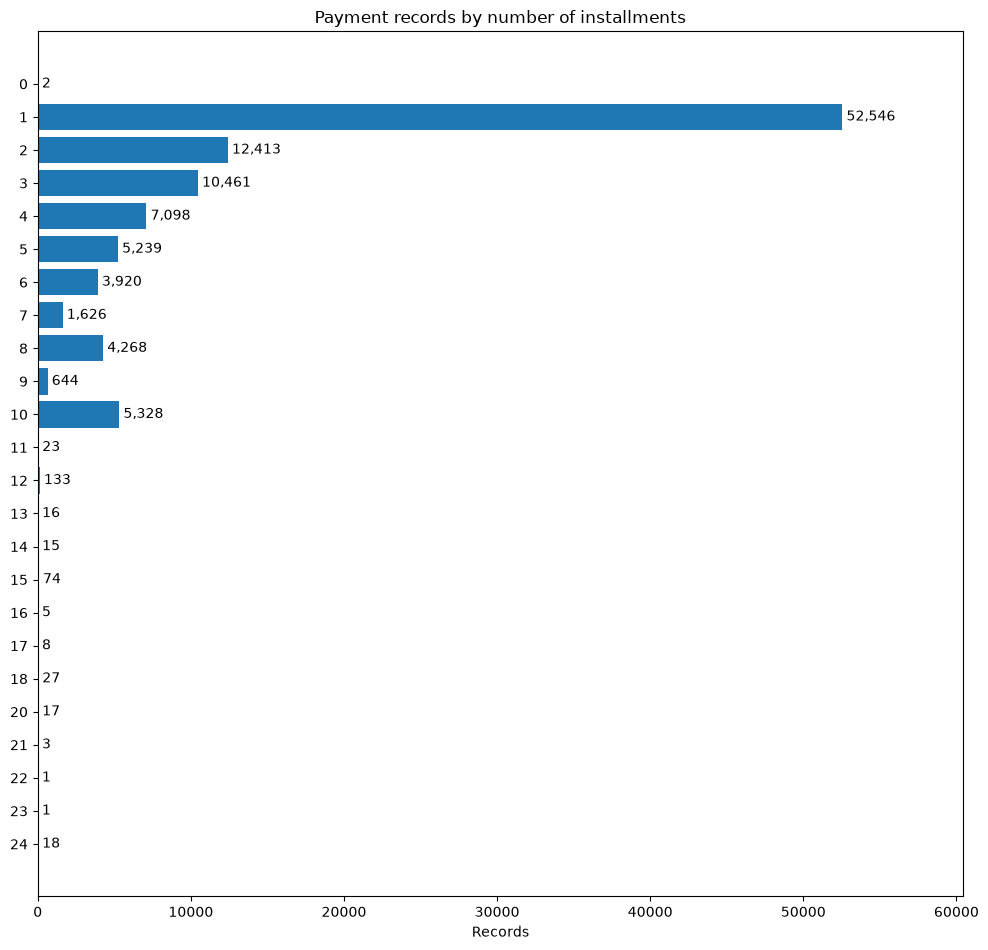

In [23]:
#payment 
bar_chart(payments["payment_type"].value_counts(), "Payment records by type", "Records")
bar_chart(payments.groupby("payment_type")["payment_value"].sum()
          .sort_values(ascending=False), "Payment value by type", "BRL")
histogram(payments["payment_value"], "Payment value", "BRL")
bar_chart(payments["payment_installments"].value_counts().sort_index(),
          "Payment records by number of installments", "Records")

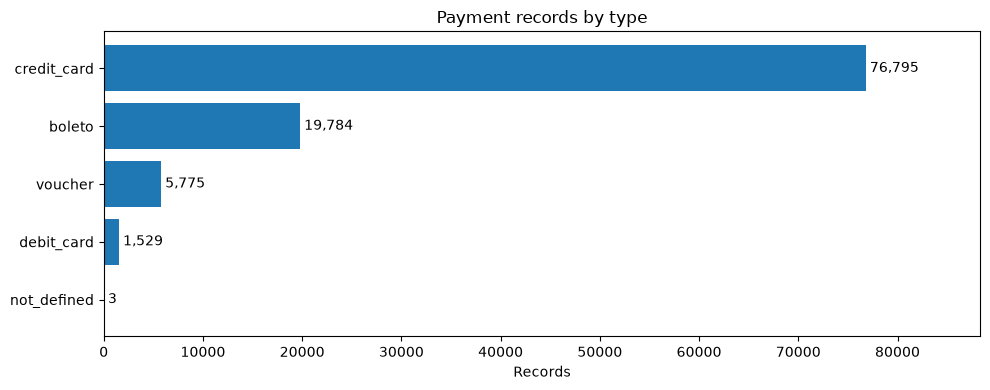

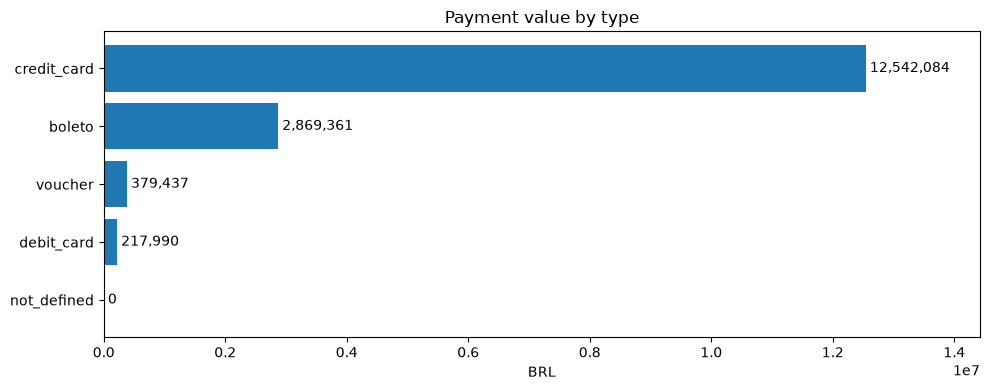

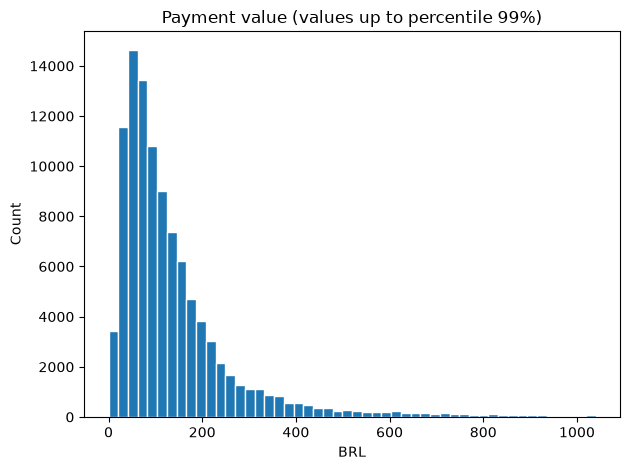

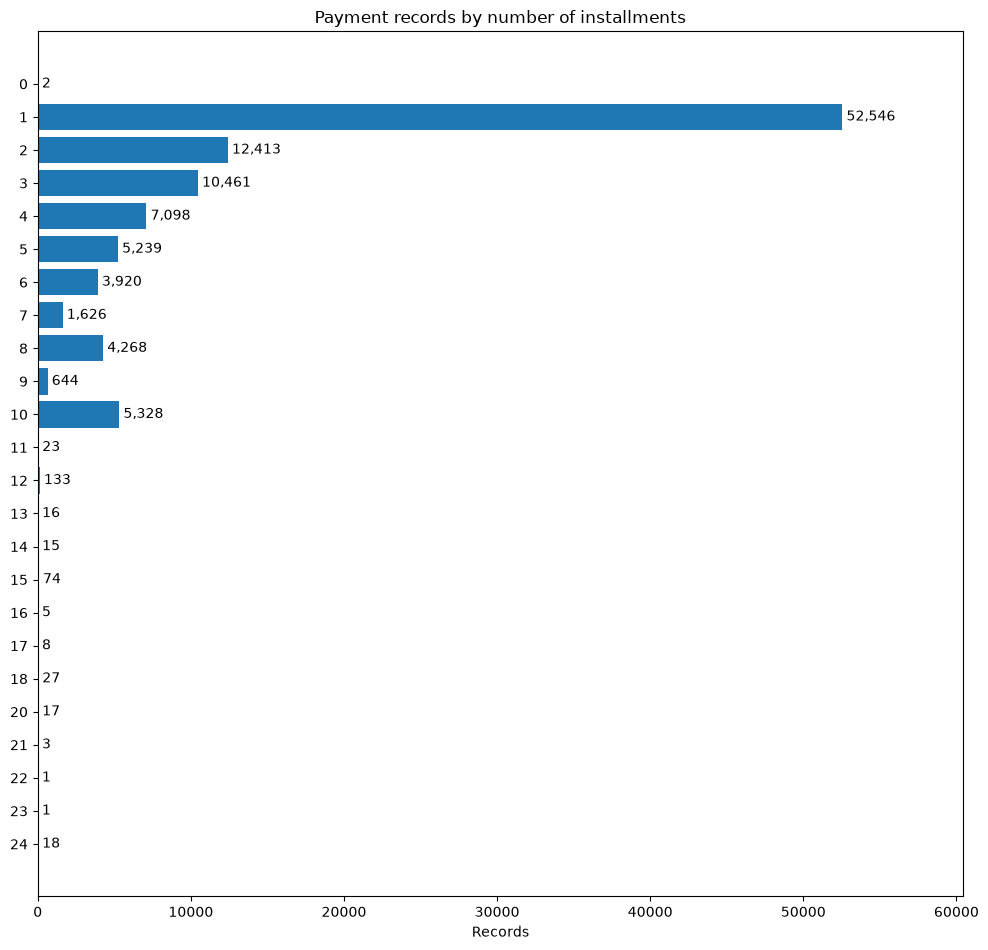

In [24]:
#payment 
bar_chart(payments["payment_type"].value_counts(), "Payment records by type", "Records")
bar_chart(payments.groupby("payment_type")["payment_value"].sum()
          .sort_values(ascending=False), "Payment value by type", "BRL")
histogram(payments["payment_value"], "Payment value", "BRL")
bar_chart(payments["payment_installments"].value_counts().sort_index(),
          "Payment records by number of installments", "Records")

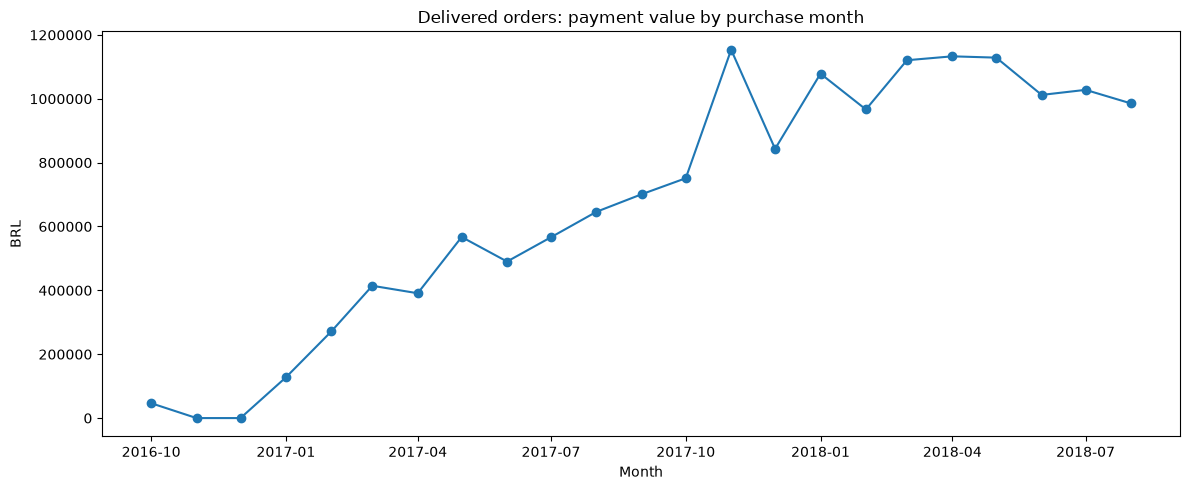

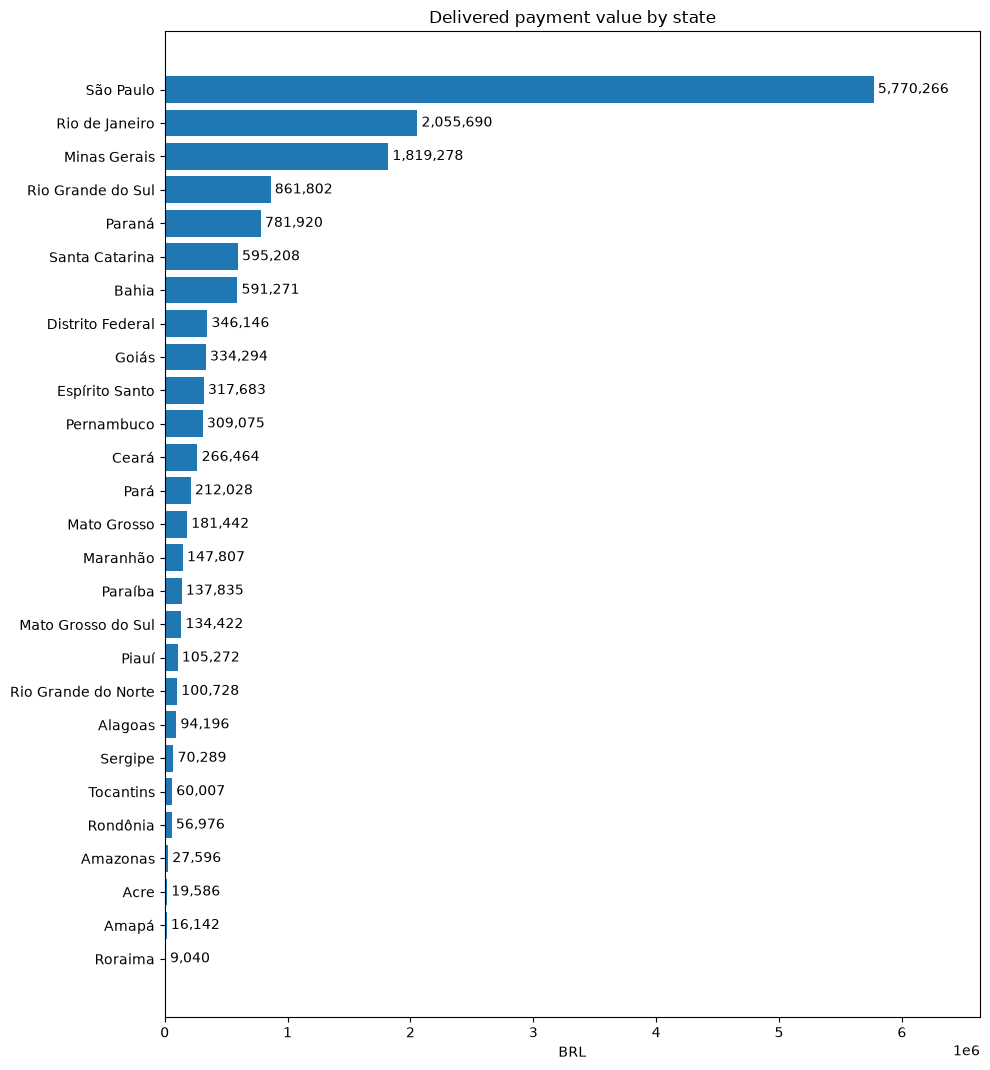

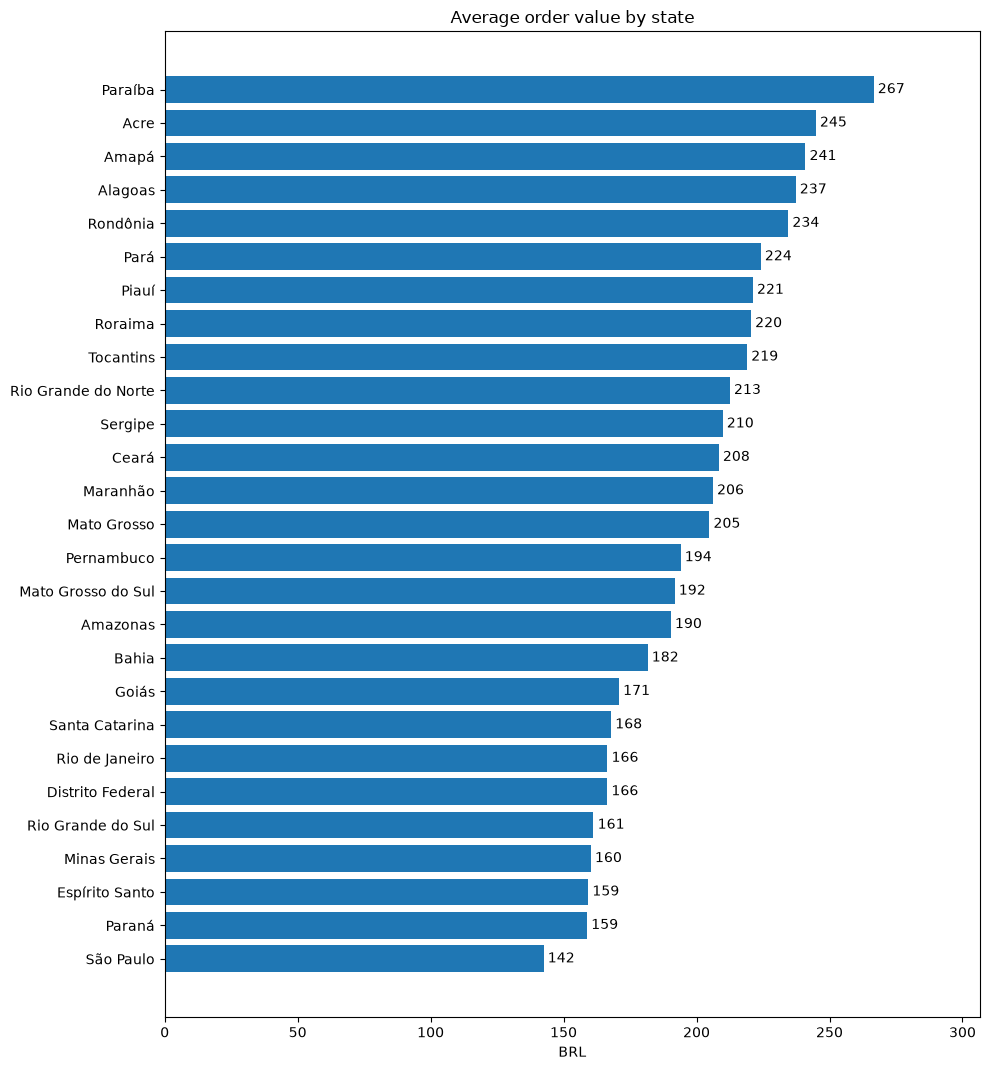

In [25]:
#delivered payment value by maonth and state
order_value = payments.groupby("order_id", as_index=False)["payment_value"].sum()
delivered = (orders[orders["order_status"] == "delivered"]
             .merge(order_value, on="order_id")
             .merge(customers[["customer_id", "customer_unique_id", "state"]],
                    on="customer_id"))

revenue = delivered.dropna(subset=["order_purchase_timestamp"]) \
    .set_index("order_purchase_timestamp").resample("MS")["payment_value"].sum()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(revenue.index, revenue.values, marker="o")
ax.set(title="Delivered orders: payment value by purchase month",
       xlabel="Month", ylabel="BRL")
ax.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

bar_chart(delivered.groupby("state")["payment_value"].sum()
          .sort_values(ascending=False), "Delivered payment value by state", "BRL")
bar_chart(delivered.groupby("state")["payment_value"].mean()
          .sort_values(ascending=False), "Average order value by state", "BRL")

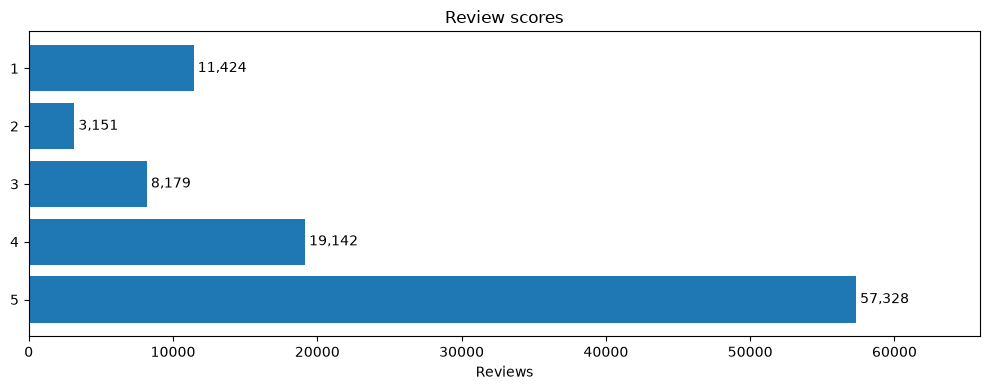

In [26]:
#review scores 
bar_chart(reviews["review_score"].value_counts().sort_index(),
          "Review scores", "Reviews")

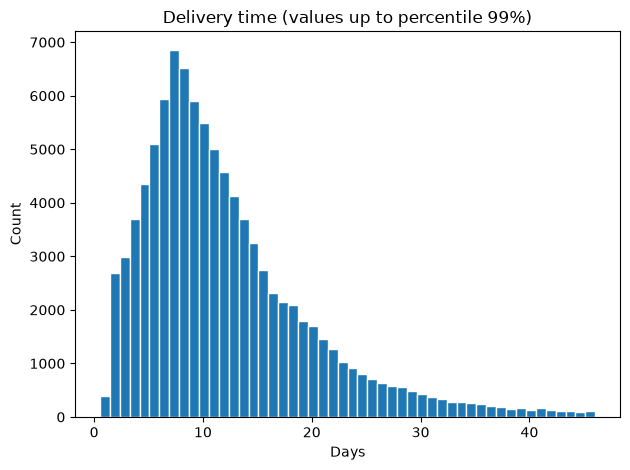

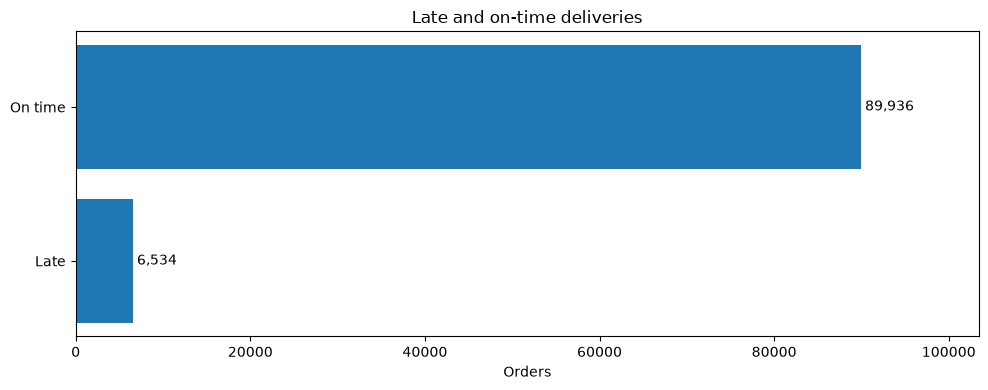

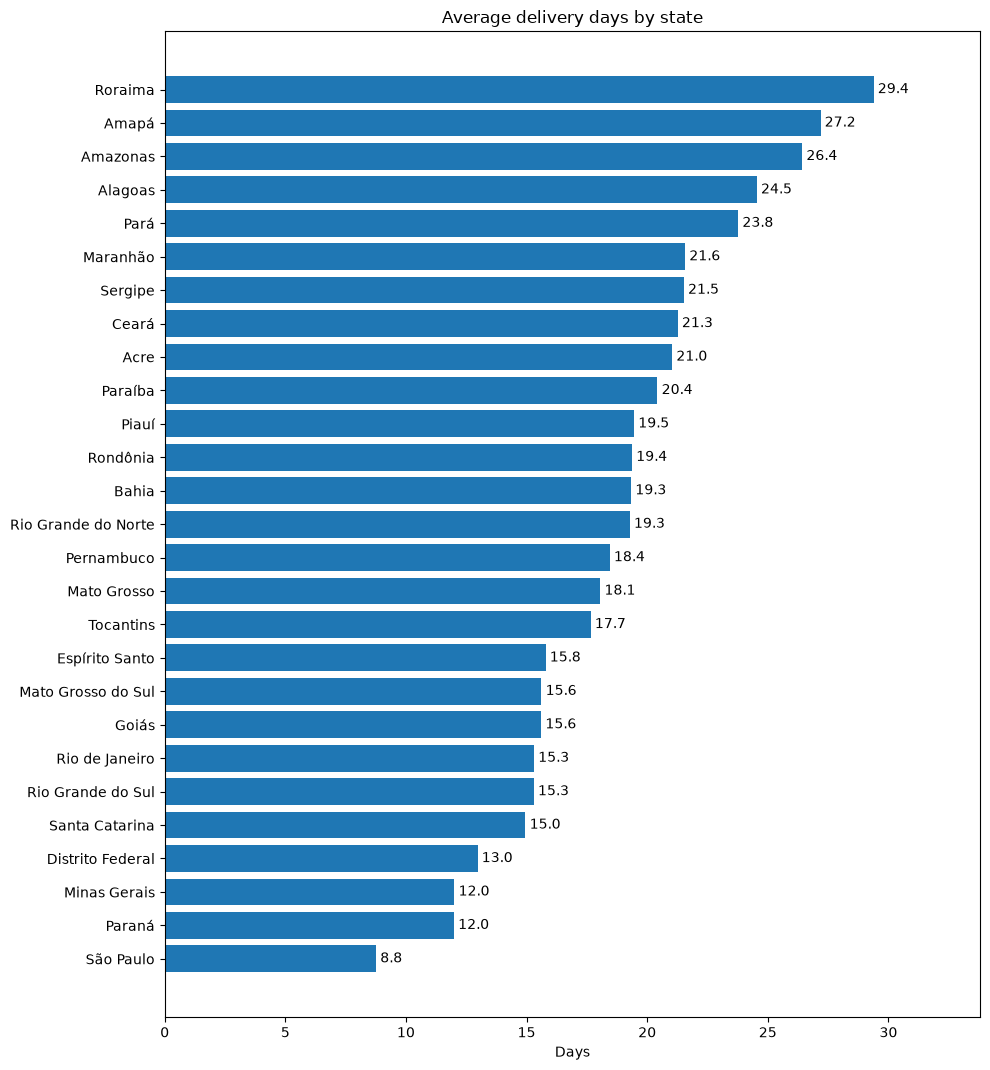

In [27]:
#delivery performance 
d = orders[orders["order_status"] == "delivered"].dropna(
    subset=["order_purchase_timestamp", "order_delivered_customer_date",
            "order_estimated_delivery_date"]).copy()
d["delivery_days"] = (d["order_delivered_customer_date"]
                      - d["order_purchase_timestamp"]).dt.total_seconds() / 86400
late = (d["order_delivered_customer_date"].dt.normalize()
        > d["order_estimated_delivery_date"].dt.normalize())
d["delivery"] = np.where(late, "Late", "On time")

histogram(d["delivery_days"], "Delivery time", "Days")
bar_chart(d["delivery"].value_counts(), "Late and on-time deliveries", "Orders")

state_delivery = d.merge(customers[["customer_id", "state"]], on="customer_id")
bar_chart(state_delivery.groupby("state")["delivery_days"].mean()
          .sort_values(ascending=False),
          "Average delivery days by state", "Days", "{:.1f}")

,count,mean,median
delivery,,,
Late,6381,2.271823,1.0
On time,89443,4.290589,5.0


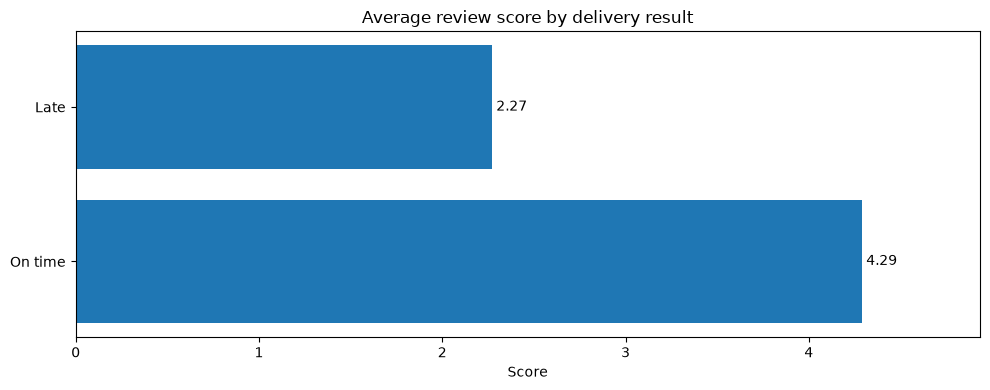

In [28]:
#delivery and review score 
review_order = reviews.groupby("order_id", as_index=False)["review_score"].mean()
dr = d.merge(review_order, on="order_id")

summary = dr.groupby("delivery")["review_score"].agg(["count", "mean", "median"])
display(summary)
bar_chart(summary["mean"], "Average review score by delivery result",
          "Score", "{:.2f}")

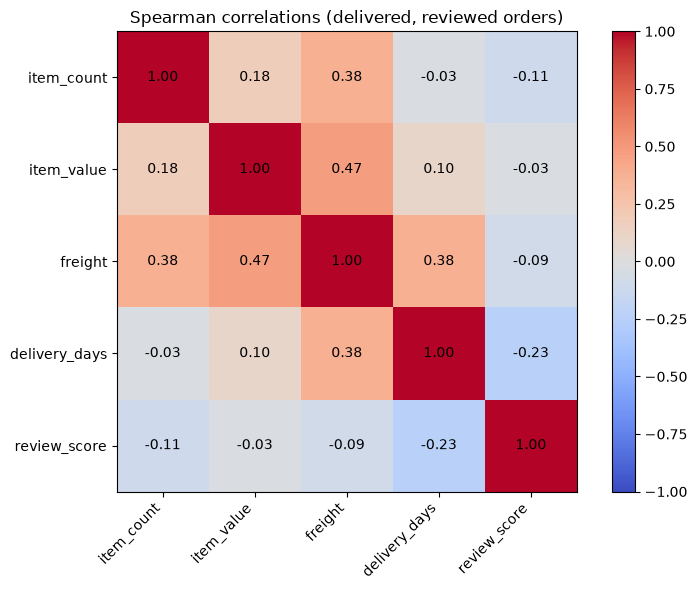

In [29]:
#coreelation 
order_items_sum = items.groupby("order_id", as_index=False).agg(
    item_count=("order_item_id", "size"),
    item_value=("price", "sum"),
    freight=("freight_value", "sum"))

corr = dr.merge(order_items_sum, on="order_id")[
    ["item_count", "item_value", "freight", "delivery_days", "review_score"]
].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
ax.set_title("Spearman correlations (delivered, reviewed orders)")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

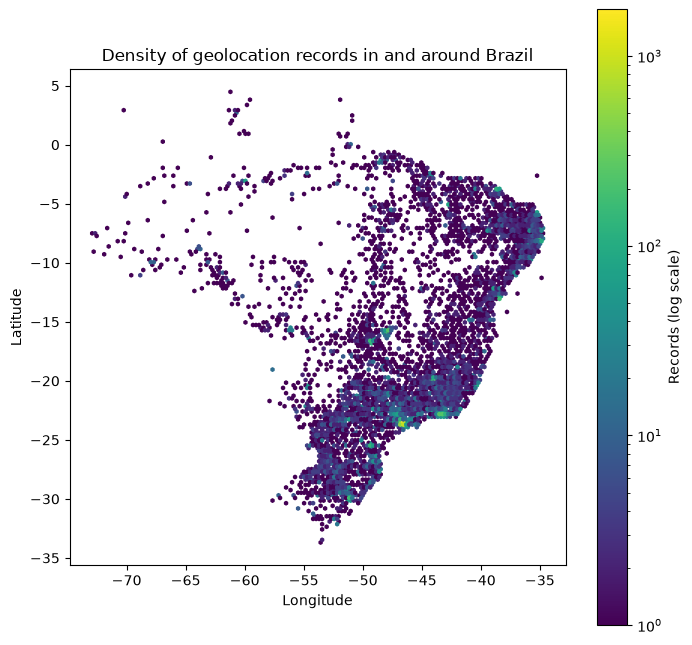

In [30]:
#Geolacation map
points = geo.dropna(subset=["geolocation_lat", "geolocation_lng"])
points = points[points["geolocation_lat"].between(-34, 6)
                & points["geolocation_lng"].between(-74, -34)]

fig, ax = plt.subplots(figsize=(8, 8))
hb = ax.hexbin(points["geolocation_lng"], points["geolocation_lat"],
               gridsize=150, bins="log", mincnt=1)
ax.set_aspect("equal")
ax.set(title="Density of geolocation records in and around Brazil",
       xlabel="Longitude", ylabel="Latitude")
fig.colorbar(hb, ax=ax, label="Records (log scale)")
plt.show()

,count,mean,std,min,25%,50%,75%,max
recency,93357.0,237.936673,152.584315,1.00,114.00,219.00,346.00,695.00
frequency,93357.0,1.033420,0.209099,1.00,1.00,1.00,1.00,15.00
monetary,93357.0,165.198772,226.314579,9.59,63.06,107.78,182.56,13664.08


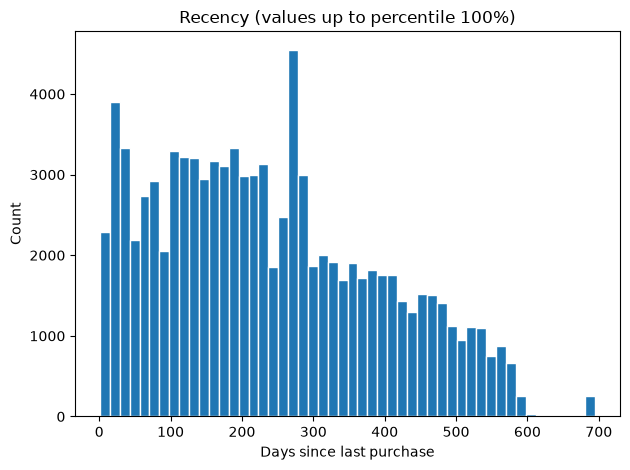

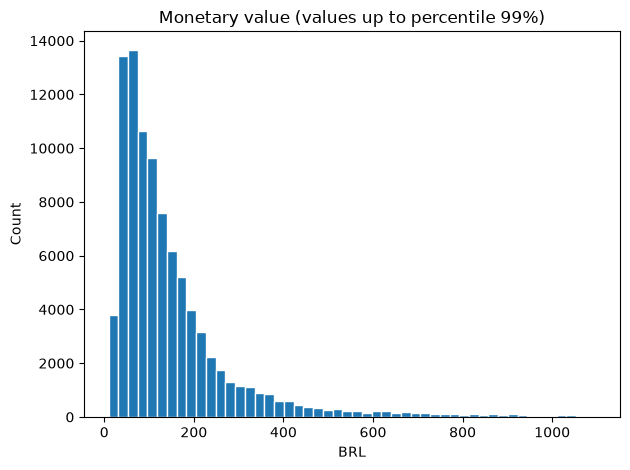

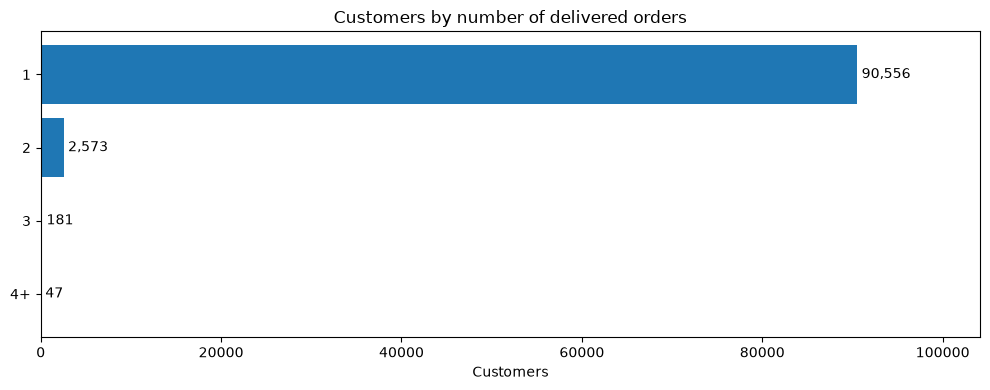

Repeat customer rate: 3.00%


In [31]:
#rfm analysis 
snapshot = delivered["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

rfm = delivered.groupby("customer_unique_id").agg(
    last_purchase=("order_purchase_timestamp", "max"),
    frequency=("order_id", "nunique"),
    monetary=("payment_value", "sum"))
rfm["recency"] = (snapshot - rfm["last_purchase"]).dt.days

display(rfm[["recency", "frequency", "monetary"]].describe().T)
histogram(rfm["recency"], "Recency", "Days since last purchase", clip=1.0)
histogram(rfm["monetary"], "Monetary value", "BRL")

freq_group = pd.cut(rfm["frequency"], [0, 1, 2, 3, np.inf],
                    labels=["1", "2", "3", "4+"])
bar_chart(freq_group.value_counts(sort=False),
          "Customers by number of delivered orders", "Customers")
print(f"Repeat customer rate: {(rfm['frequency'] > 1).mean():.2%}")

,customers,avg_recency,avg_value,total_value
segment,,,,
Recent high value,22554,112.01,261.17,5890418.43
Older high value,21761,364.75,263.72,5738894.68
Older lower value,23497,365.14,63.69,1496413.15
Recent lower value,22744,112.24,62.98,1432378.30
Repeat,2801,220.29,308.59,864357.21


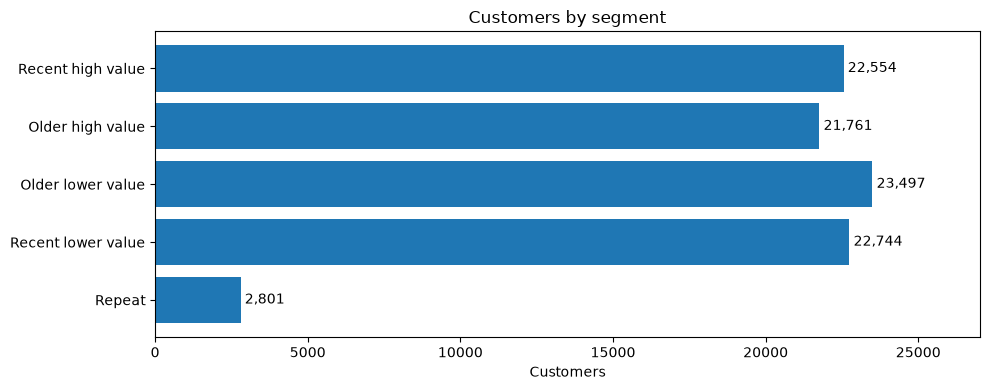

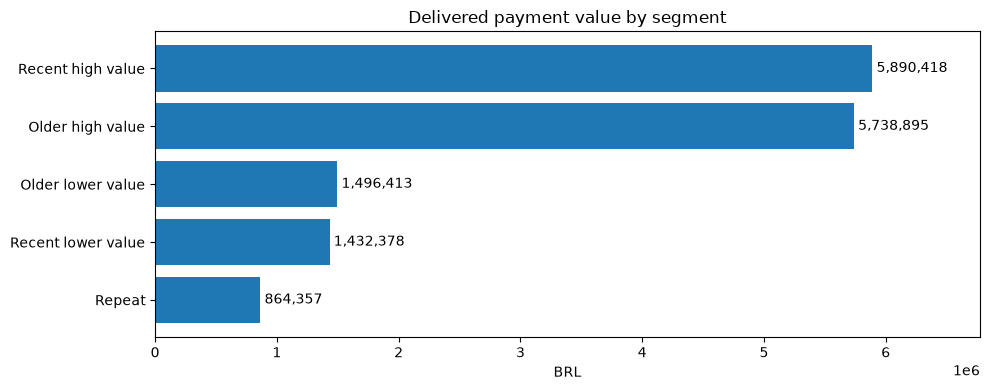

In [33]:
#customer segments
rfm["r_high"] = rfm["recency"] <= rfm["recency"].median()
rfm["m_high"] = rfm["monetary"] >= rfm["monetary"].median()

rfm["segment"] = np.select(
    [rfm["frequency"] > 1,
     rfm["r_high"] & rfm["m_high"],
     ~rfm["r_high"] & rfm["m_high"],
     rfm["r_high"] & ~rfm["m_high"]],
    ["Repeat", "Recent high value", "Older high value", "Recent lower value"],
    default="Older lower value")

segments = rfm.groupby("segment").agg(
    customers=("monetary", "size"), avg_recency=("recency", "mean"),
    avg_value=("monetary", "mean"), total_value=("monetary", "sum")
).sort_values("total_value", ascending=False)
display(segments.round(2))

bar_chart(segments["customers"], "Customers by segment", "Customers")
bar_chart(segments["total_value"], "Delivered payment value by segment", "BRL")